In [2]:
!pip install imbalanced-learn

In [4]:
import sys
!{sys.executable} -m pip install imbalanced-learn

  Using cached imbalanced_learn-0.12.4-py3-none-any.whl.metadata (8.3 kB)
Using cached imbalanced_learn-0.12.4-py3-none-any.whl (258 kB)
  Attempting uninstall: joblib
    Found existing installation: joblib 1.1.0
    Uninstalling joblib-1.1.0:
      Successfully uninstalled joblib-1.1.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [imbalanced-learn]1/2 [imbalanced-learn]

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Users/reemfouda/opt/anaconda3/bin/python -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

In [8]:
df = pd.read_csv('/Users/reemfouda/Desktop/Telco-Customer-Churn.csv')

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


if 'customerID' in df.columns:
    df.drop('customerID', axis=1, inplace=True)


df['Churn'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

X = df.drop('Churn', axis=1)
y = df['Churn']

In [9]:
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [10]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train)

print(f"Original training shape: {X_train_processed.shape}")
print(f"Resampled training shape: {X_train_resampled.shape}")

Original training shape: (5634, 30)
Resampled training shape: (8278, 30)


In [11]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_resampled, y_train_resampled)

#ROC-AUC
y_pred_rf_proba = rf_model.predict_proba(X_test_processed)[:, 1]
rf_auc = roc_auc_score(y_test, y_pred_rf_proba)
print(f"Random Forest ROC-AUC Score: {rf_auc:.4f}")

Random Forest ROC-AUC Score: 0.8223


In [12]:
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_resampled, y_train_resampled)

#ROC-AUC
y_pred_xgb_proba = xgb_model.predict_proba(X_test_processed)[:, 1]
xgb_auc = roc_auc_score(y_test, y_pred_xgb_proba)
print(f"XGBoost ROC-AUC Score: {xgb_auc:.4f}")

XGBoost ROC-AUC Score: 0.8370


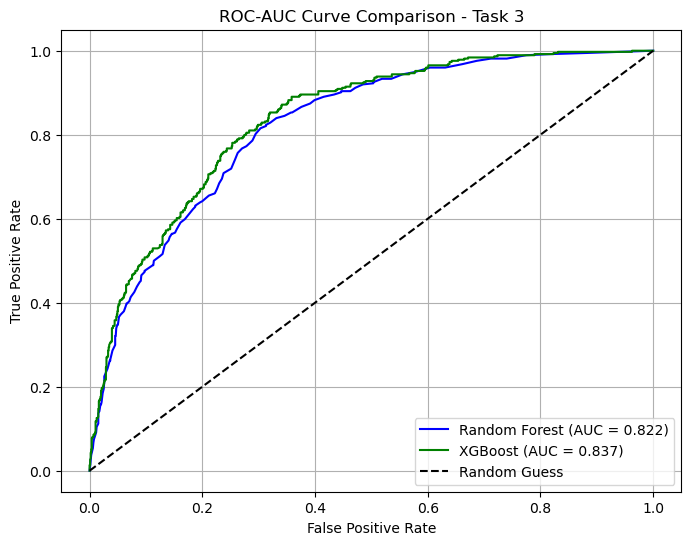

In [13]:
plt.figure(figsize=(8, 6))

#Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf_proba)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_auc:.3f})', color='blue')

# XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_xgb_proba)
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {xgb_auc:.3f})', color='green')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve Comparison - Task 3')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

Top 10 Most Influential Features:
                           Feature  Importance
1                           tenure    0.140444
3                     TotalCharges    0.137753
2                   MonthlyCharges    0.121907
25               Contract_Two year    0.064911
28  PaymentMethod_Electronic check    0.061291
13              OnlineSecurity_Yes    0.048633
10     InternetService_Fiber optic    0.039478
24               Contract_One year    0.036407
26            PaperlessBilling_Yes    0.035924
19                 TechSupport_Yes    0.034251


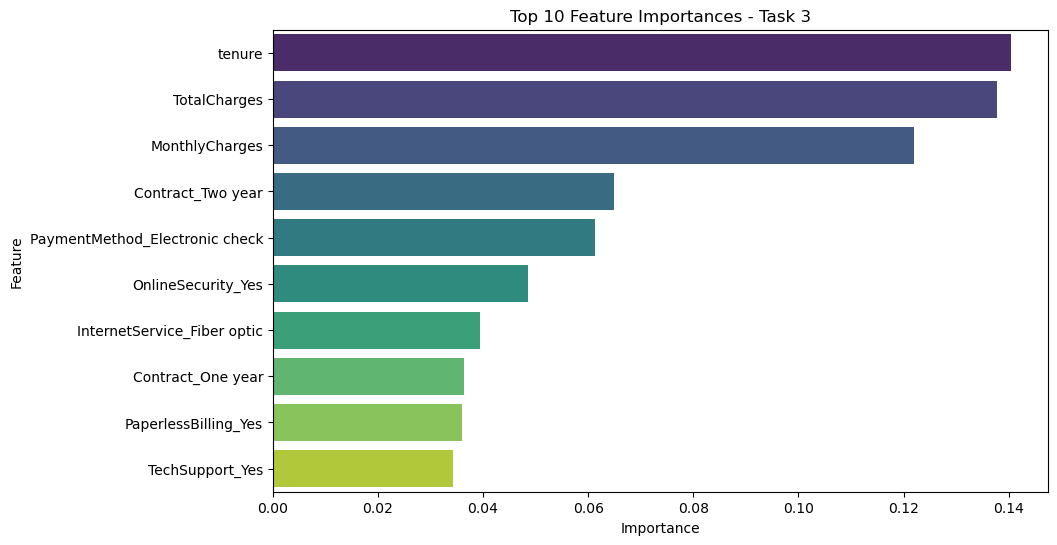

In [14]:
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_features = list(numerical_cols) + encoded_cat_cols

importances = rf_model.feature_importances_
feature_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})
top_10_features = feature_imp_df.sort_values(by='Importance', ascending=False).head(10)

print("Top 10 Most Influential Features:")
print(top_10_features)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=top_10_features, palette='viridis')
plt.title('Top 10 Feature Importances - Task 3')
plt.show()